## **[실습 1-1] Linear Regression 모델 생성, 학습, 예측**

### **1. 데이터 생성**

**Q1. 아래의 4개의 점을 가진 데이터를 하드코딩하여 생성한다.**
```
(2,2), (3,4), (4,6), (6,7)
```
이 데이터의 X값은 독립변수, y값은 종속변수 (정답) 이라고 가정한다.

In [7]:
import sklearn

In [23]:
#code here
import numpy as np
# input
X = np.array([2, 3, 4, 6])
# target
y = np.array([2, 4, 6, 7])


### **2. 데이터 시각화**

**Q1. 생성된 4개의 점을 scatterplot으로 시각화한다.**

In [29]:
import matplotlib.pyplot as plt 
plt.rcParams['font.family'] = 'Malgun Gothic' 
plt.rcParams['axes.unicode_minus'] = False

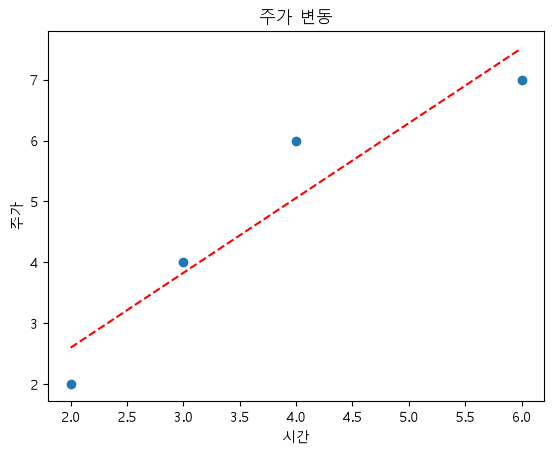

In [ ]:
#code here
import seaborn
import matplotlib.pyplot as plt

#Line of Best Fit의 답을 한번 그려보기
𝑦_pred = 1.22857142857 * X + 0.14285714286

plt.title("주가 변동")
plt.xlabel("시간")
plt.ylabel("주가")
plt.scatter(X,y)
plt.plot(X, y_pred, color = 'red', linestyle='--')
plt.show()

### **3. 모델 생성하기**

**Q1. LinearRegression class를 생성한다.**

- OLS (Orinary Least Squares) 공식을 응용하여 w(coefficient), b(intercept)를 구한다.

In [31]:
#code here
# 모델이 하는 행동 3가지
# 1. parameter 조정을 한다. (parameter = 함수에서 보던 parameter랑은 다르다.)
# -> 모델의 parameter => 모델이 학습하면서 알아서 조정하는 가중치 값들을 의미한다.
# -> 사람이 건드는게 아니라, 모델이 알아서 구하는 값들 => 선형회귀에서는 y = mx+b => m(coefficient)와 b(bias/intercept)를 알아서 구해서 간직

# 2. 학습 (train)
# 저희가 주어주는 데이터와 답을 기반으로 -> parameter를 조정

# 3. 예측 (predict)
# 새로운 데이터가 들어왔을 때, 너가 학습한 (배운/가지고 있는) parameter들을 기반으로, 너의 공식대로 예측값을 뽑아내라

class LinearRegression:

  def __init__(self):
    # parameter 정의
    #1. 기울기값, 2.절편값(bias)
    self.w = None # 기울기
    self.b = None 
  
  # 학습 메소드 -> 이 과정을 통해서 parameter 값들을 계산해서 찾는것.
  def fit(self, X, y):
    n = X.size # (요소의 개수)
    # 𝑏0 = (𝑛∑𝑥𝑦 − ∑𝑥∑𝑦) / (𝑛∑𝑥² − (∑𝑥)²)
    xy_sum = np.sum(X * y) # ∑𝑥𝑦
    x_sum = np.sum(X)  #∑𝑥
    y_sum = np.sum(y)  #∑𝑦
    x_squared_sum = np.sum(X**2) #∑𝑥²
    self.w = ((n * xy_sum) - (x_sum * y_sum)) / ((n * x_squared_sum) - (x_sum) ** 2) 
    # 𝑏1 = (∑𝑦 – 𝐵0∑𝑥) / 𝑛
    self.b = (y_sum - (self.w * x_sum)) / n

  # 예측 메소드 -> 새로운 정보를 전달했을때, 가진 paramter를 기반으로 예측값을 뽑아내기 
  def predict(self, X):
    y_pred = self.w * X + self.b # 선형 방정식 -> fit을 통해 찾은 w와 b를 써서 그 선에 있는 예측값을 뽑아낸다.
    return y_pred

### **4. 학습하기**

**Q. 위에서 만들어진 Linear Regression 모델의 instance를 생성한다.**

그리고 생성한 X, y 데이터를 활용하여 학습시킨다.

In [32]:
#code here
# input
X = np.array([2, 3, 4, 6])
# target
y = np.array([2, 4, 6, 7])
model = LinearRegression()
model.fit(X, y)

print(model.w)
print(model.b)



1.2285714285714286
0.14285714285714235


### **5. 예측하기**

**학습이 완료된 모델에 다시 X 데이터를 넣어 결과를 예측한다.**

결과는 y_pred (y_예측)이라는 변수에 저장하고, 출력해자.

In [33]:
#code here

data = np.array([1, 3, 4, 9])
# 예측
y_pred = model.predict(data)
print(y_pred) 

[ 1.37142857  3.82857143  5.05714286 11.2       ]


### **6. 결과 시각화하기**

**기존에 시각화했던 scatterplot에 model이 학습한 Line of Best Fit을 그려보자.**
- Line of Best Fit의 색은 빨간색으로, 파선으로 그린다.
- label은 "Line of Best Fit"이라고 하여, plot내에 나타나도록 해보자.

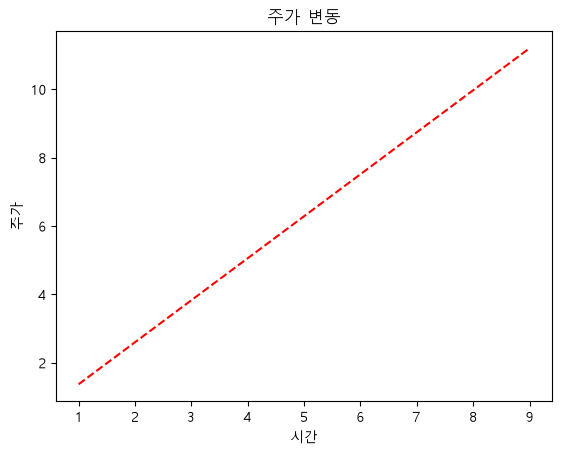

In [37]:
#code here
import matplotlib.pyplot as plt
plt.title("주가 변동")
plt.xlabel("시간")
plt.ylabel("주가")
plt.plot(np.arange(1,10), model.predict(np.arange(1,10)), color="red", linestyle="--")
plt.show() 

## **실습[1-2] 모델 평가하기**

**Q1. MAE (Mean Absolute Error) 함수 작성하기**

MAE 함수를 작성하고, 모델 성능을 평가한다.

In [41]:
# code here
def mae(y_true, y_pred):
#(1/𝑛) Σ|𝑦ᵢ − ŷᵢ| 
  return np.mean(np.abs(y_true - y_pred))

**Q2. MSE (Mean Squared Error) 함수 작성하기**

MSE 함수를 작성하고, 모델 성능을 평가한다.

In [49]:
# code here
def mse(y_true, y_pred):
  #(1/𝑛) Σ(𝑦ᵢ − ŷᵢ)²
  return np.mean((y_true - y_pred)**2)

**Q3. RMSE (Root Mean Squared Error) 함수 작성하기**

RMSE 함수를 작성하고, 모델 성능을 평가한다.

In [47]:
# code here
def rmse(y_true, y_pred):
  #root((1/𝑛) Σ(𝑦ᵢ − ŷᵢ)²)
  return  np.sqrt(np.mean((y_true - y_pred)**2))

**4. r2_score 함수 작성하기**

r2_score 함수를 작성하고, 모델 성능을 평가한다.

In [40]:
# code here
def r2_score(y_true, y_pred):
  sse = np.sum((y_true - y_pred) ** 2)
  sst = np.sum((y_true - np.mean(y_true)) ** 2)
  return 1 - sse/sst

**5. 모든 결과 출력**

MAE : ...<br>
MSE : ...<br>
RMSE : ...<br>
R2-score : ...<br>

의 형태로 출력한다.

In [51]:
# code here
y_pred = model.predict(X)

print(f"MAE : {mae(y, y_pred)}")
print(f"MSE : {mse(y, y_pred)}")
print(f"RMSE : {rmse(y, y_pred)}")
print(f"R2_score : {r2_score(y, y_pred)}")

MAE : 0.5571428571428572
MSE : 0.3857142857142857
RMSE : 0.6210590034081188
R2_score : 0.8953995157384989
